In [1]:
# importation des premieres bibliotheques necessaires
import pandas as pd
import numpy as np
import seaborn as sns
import plotly.express as px
import joblib as jb
import matplotlib.pyplot as plt

In [2]:
#suppression des warnings
import warnings
warnings.filterwarnings("ignore")

## Description des variables

Le jeu de données contient **5 507 annonces de voitures** décrites par **6 variables** : 5 variables explicatives et 1 variable cible (`Venant_Occasion`).

| Variable | Type | Description | Valeurs / plage observée |
|---|---|---|---|
| `Marque` | Catégorielle | Marque de la voiture | 46 marques (Ford, Kia, Hyundai, Mercedes-Benz, Toyota...) |
| `Année` | Numérique (discrète) | Année du véhicule | 1990 – 2024 (médiane = 2015) |
| `Boite_Vitesse` | Catégorielle | Type de boîte de vitesse | `Automatique`, `Manuelle`, `Tiptronic` |
| `Adresse` | Catégorielle | Quartier de l'annonce | 182 écritures dans le fichier brut, soit 85 adresses réelles après nettoyage (Almadies, VDN, Plateau...) |
| `Prix` | Numérique (continue) | Prix de la voiture | 1 – 779 414 131 (médiane = 7 800 000) |
| **`Venant_Occasion`** | Catégorielle | **Variable cible** : origine / état du véhicule | `Venant` (2 855 annonces), `D'occasion` (2 652 annonces) |

In [3]:
# importation et premiere appercue de nos donnees
df = pd.read_csv("Car_Data (1).csv")
df.head(15)

,Marque,Année,Boite_Vitesse,Adresse,Prix,Venant_Occasion
0,Mitsubishi,2017,Automatique,"Liberte 6,Dakar",9750000,Venant
1,Ford,2009,Manuelle,"Yoff,Dakar",2500000,D'occasion
2,BMW,2015,Automatique,"Cité Damel,Dakar",15500000,D'occasion
3,Ford,2013,Automatique,"Almadies,Dakar",3800000,D'occasion
4,GMC,2014,Automatique,"Hlm,Dakar",7500000,Venant
5,Mitsubishi,2014,Manuelle,"VDN,Dakar",13500000,Venant
6,Peugeot,2015,Automatique,"Yoff,Dakar",6000000,Venant
7,Porsche,2018,Automatique,"Plateau,Dakar",25000000,Venant
8,Kia,2012,Automatique,"Parcelles Assainies,Dakar",5700000,D'occasion
9,Ford,2013,Automatique,"Liberte 6 extension,Dakar",5800000,D'occasion


In [4]:
# Dimension de notre jeu de donnees
df.shape

(5507, 6)

In [5]:
# info sur les donnees
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5507 entries, 0 to 5506
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Marque           5507 non-null   str  
 1   Année            5507 non-null   int64
 2   Boite_Vitesse    5507 non-null   str  
 3   Adresse          5507 non-null   str  
 4   Prix             5507 non-null   int64
 5   Venant_Occasion  5507 non-null   str  
dtypes: int64(2), str(4)
memory usage: 258.3 KB


### <font color = 'teal'>Exploration et preparation des données<font>

###### <font color = 'bisque'> Nettoyage de la colonne Adresse

In [6]:
# Nombre d'adresses distinctes avant nettoyage
# (la même adresse est écrite de plusieurs façons : espace en trop devant, ou après la virgule)
print(df['Adresse'].nunique())
df['Adresse'].unique()[:10]

182


<StringArray>
[          'Liberte 6,Dakar',                'Yoff,Dakar',
          'Cité Damel,Dakar',            'Almadies,Dakar',
                 'Hlm,Dakar',                 'VDN,Dakar',
             'Plateau,Dakar', 'Parcelles Assainies,Dakar',
 'Liberte 6 extension,Dakar',            'Colobane,Dakar']
Length: 10, dtype: str

In [8]:
# Nettoyage de la colonne Adresse
# 1) supprimer les espaces autour de la virgule et en début/fin de texte
#    ex : ' Almadies,Dakar' et 'Almadies, Dakar' deviennent 'Almadies,Dakar'
df['Adresse'] = df['Adresse'].str.replace(r"\s*,\s*", ",", regex = True).str.strip()
# 2) harmoniser la seule adresse écrite avec deux majuscules différentes
df['Adresse'] = df['Adresse'].replace({'Lac rose,Dakar': 'Lac Rose,Dakar'})
# 3) retirer la mention 'Dakar' : on ne garde que la partie avant la virgule (le quartier)
#    ex : 'Almadies,Dakar' devient 'Almadies'
df['Adresse'] = df['Adresse'].str.split(',').str[0]


In [ ]:
# Nombre d'adresses distinctes après nettoyage
print(df['Adresse'].nunique())
df['Adresse'].unique()[:10]

###### <font color = 'bisque'> Selection des variables catégorielles et quantitatives

In [ ]:
# selection les variables catégorielles
categoriel_data = df.select_dtypes(exclude = 'number')
categoriel_data

In [11]:
# selection des donnees quantitative
quant_data = df.select_dtypes(include = "number")
quant_data.head()

,Année,Prix
0,2017,9750000
1,2009,2500000
2,2015,15500000
3,2013,3800000
4,2014,7500000


###### <font color = 'bisque'> Exploration des variables catégorielles

In [ ]:
# décrire les variables catégorielles
categoriel_data.describe()

In [13]:
# fonction de countplot
import plotly.express as px
def countplot_func(col):
    val  = df[col].value_counts()
    fig = px.bar(x = val.index, y = val.values, color =val.index.astype(str) , text_auto = True)
    fig.show()

In [ ]:
for col in categoriel_data:
    countplot_func(col)

###### <font color = 'bisque'> Exploration des variables quantitatives

In [15]:
# décrire les variables quantitatives
quant_data.describe()

,Année,Prix
count,5507.000000,5.507000e+03
mean,2014.508444,1.110512e+07
std,3.089839,1.619639e+07
min,1990.000000,1.000000e+00
25%,2013.000000,4.600000e+06
50%,2015.000000,7.800000e+06
75%,2016.000000,1.250000e+07
max,2024.000000,7.794141e+08


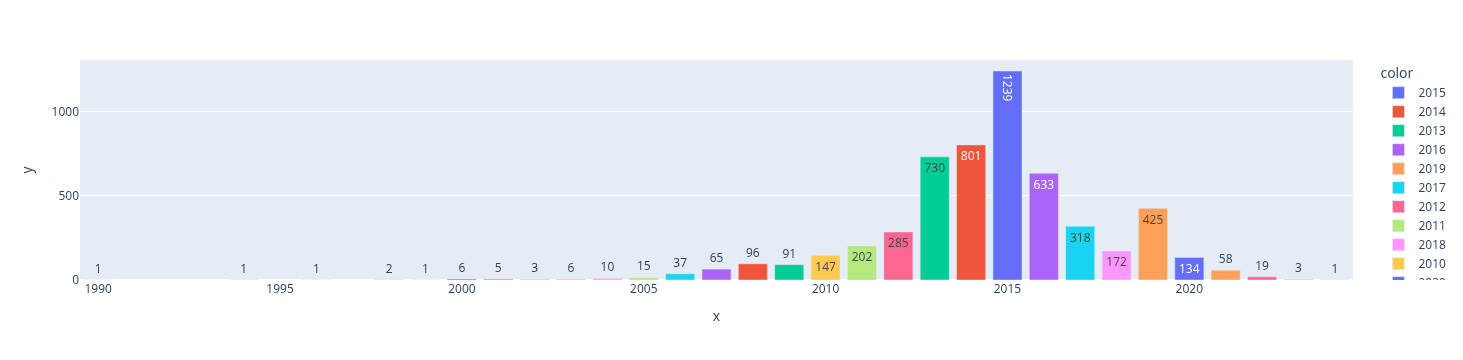

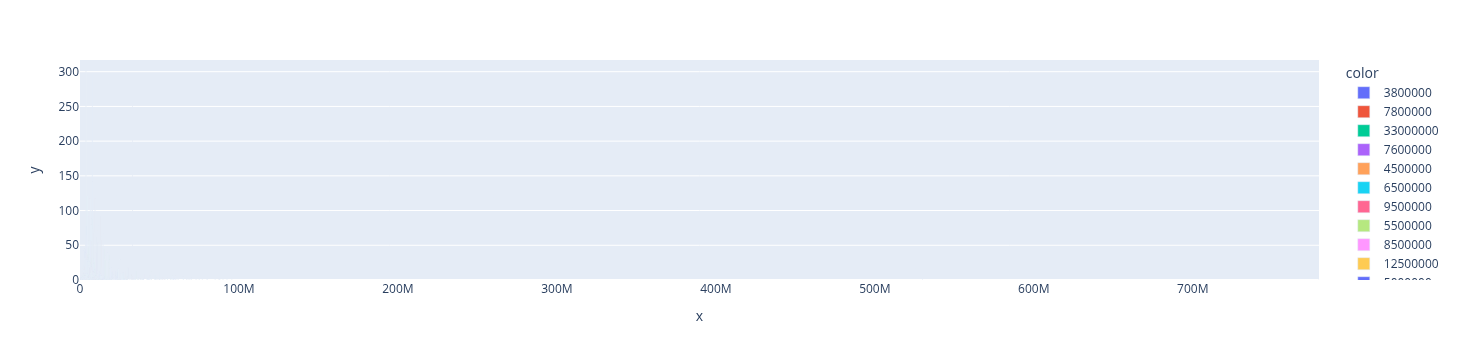

In [16]:
# countplot des variables quantitatives
for col in quant_data:
    countplot_func(col)

In [17]:
# fonction de visualisation des boxplots
def boxplot_func(col):
  plt.figure(figsize=(25,3))
  sns.boxplot(x=df[col])
  plt.show()

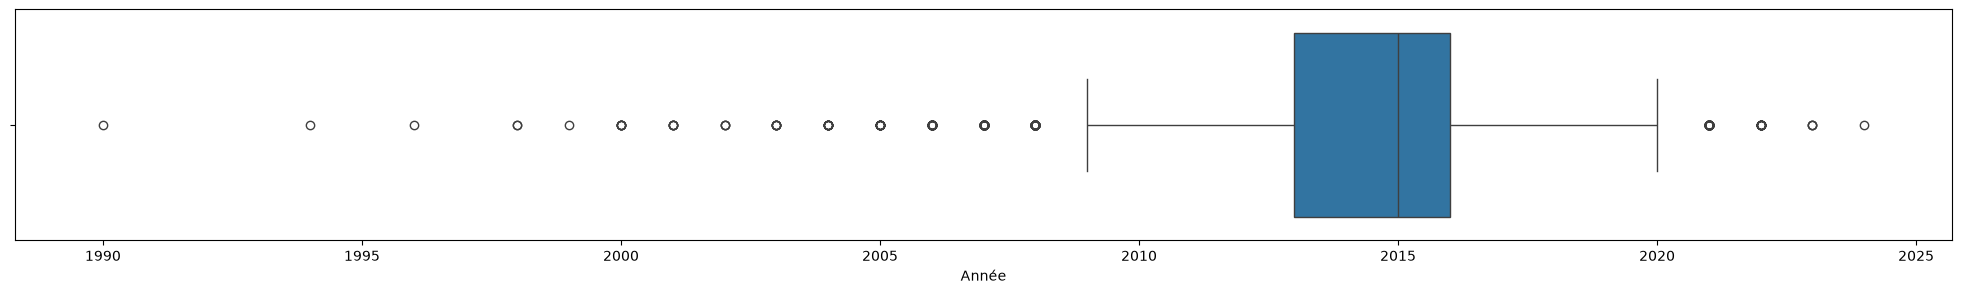

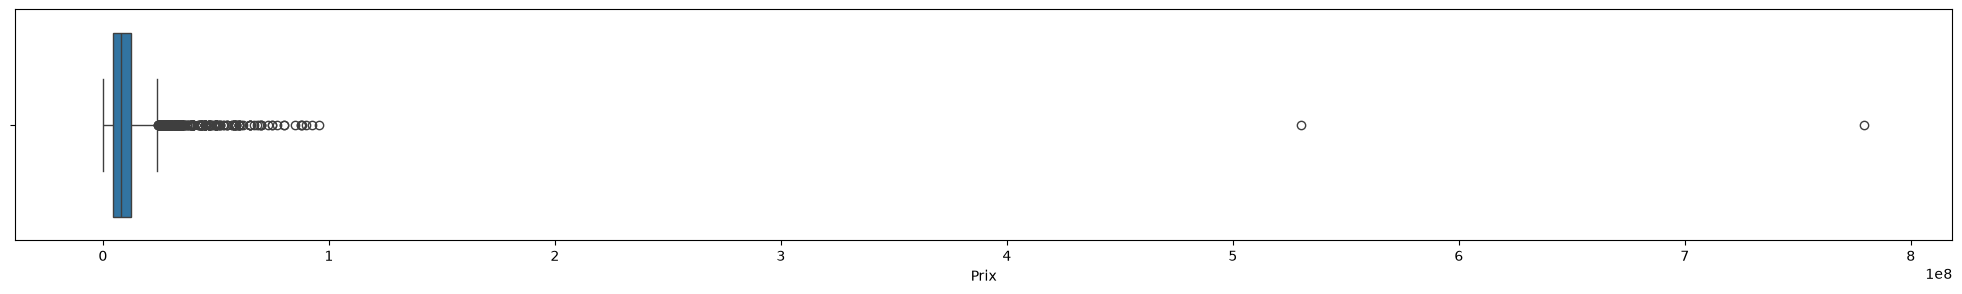

In [18]:
# boxplots des variables quantitatives
for col in quant_data:
    boxplot_func(col)

###### <font color = 'bisque'> Preparation des données

In [19]:
# vérification des valeurs manquantes (il n'y en a pas dans ce jeu de données)
df.isna().sum()

Marque             0
Année              0
Boite_Vitesse      0
Adresse            0
Prix               0
Venant_Occasion    0
dtype: int64

In [20]:
# Enregistrement des valeurs uniques des variables catégorielles explicatives (listes déroulantes du déploiement)
uniques = {col: np.unique(df[col]).tolist() for col in categoriel_data.columns if col != 'Venant_Occasion'}
# sauvegarde
jb.dump(uniques, "./models/voiture_uniques.joblib")
uniques['Boite_Vitesse']

['Automatique', 'Manuelle', 'Tiptronic']

In [21]:
# Encoder les variables catégorielles
from sklearn.preprocessing import LabelEncoder

# un encodeur par variable catégorielle (target 'Venant_Occasion' comprise), rangés dans un dictionnaire
encoders = {}
for col in categoriel_data.columns:
    encoder = LabelEncoder()
    df[col] = encoder.fit_transform(df[col])
    encoders[col] = encoder

# classes de la variable cible, dans l'ordre de leurs codes 0 et 1
classnames = encoders['Venant_Occasion'].classes_
classnames

array(["D'occasion", 'Venant'], dtype=object)

In [22]:
# sauvegarde des encodeurs
jb.dump(encoders, "./models/voiture_encoders.joblib")

['./models/voiture_encoders.joblib']

In [23]:
from sklearn.impute import KNNImputer
# fonction d'imputation des valeurs aberrantes
# (définie mais NON appliquée ici, comme dans le notebook des téléphones)
def impute_func(df, col, n_neighbors=5):
    # 2. Détection des outliers (Méthode IQR)
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    min_value = Q1 - 1.5 * IQR
    max_value = Q3 + 1.5 * IQR

    # Les valeurs hors bornes deviennent des valeurs manquantes pour le KNNImputer
    df.loc[(df[col] < min_value) | (df[col] > max_value), col] = np.nan
    # n_neighbors : nombre de voisins pour calculer la moyenne de remplacement
    imputer = KNNImputer(n_neighbors=n_neighbors)
    df[:] = imputer.fit_transform(df)

In [24]:
# Application du traitement valeurs aberantes
for col in quant_data :
    impute_func(df,col)

In [25]:
# Fractionner les données en variables prédicteurs (x) et variable cible (y)
x = df.drop('Venant_Occasion', axis = 1).values
y = df.Venant_Occasion.values

# ordre des variables explicatives (à respecter lors des prédictions)
features = df.drop('Venant_Occasion', axis = 1).columns.tolist()
jb.dump(features, "./models/voiture_features.joblib")
features

['Marque', 'Année', 'Boite_Vitesse', 'Adresse', 'Prix']

In [26]:
# splitter les données en train, val et test
# train (80%), val(10%) et test(10%)
#train : données d'entrainement, val: données utiliser pour évaluer chaque modèle et test: données pour tester le modèle le plus performant

from sklearn.model_selection import train_test_split
x_train, x_val_test, y_train, y_val_test = train_test_split(x, y, train_size = 0.8, random_state = 42)
x_val, x_test, y_val, y_test = train_test_split(x_val_test, y_val_test, train_size = 0.5, random_state = 42)

In [27]:
# normaliser les données : le scaler est ajusté sur le train uniquement, puis appliqué à val et test
from sklearn.preprocessing import MinMaxScaler # Z = (X -Xmin)/(Xmax -Xmin)
scaler = MinMaxScaler()
x_train = scaler.fit_transform(x_train)
x_val = scaler.transform(x_val)
x_test = scaler.transform(x_test)
x_train[:5]

array([[0.62222222, 0.90909091, 0.        , 0.01190476, 0.70916665],
       [0.73333333, 0.        , 0.        , 0.75      , 0.17499997],
       [0.6       , 0.45454545, 0.        , 0.79761905, 0.39583331],
       [0.28888889, 0.72727273, 0.        , 0.92857143, 0.58333332],
       [0.77777778, 0.45454545, 0.        , 0.0952381 , 0.2583333 ]])

In [28]:
# sauvegarde du scaler
jb.dump(scaler, "./models/voiture_scaler.joblib")

['./models/voiture_scaler.joblib']

### <font color = 'teal'>Fonctions d'évaluation<font>

In [29]:
# fonction d'évaluation
from sklearn.metrics import f1_score, accuracy_score
def evaluation(model):
  y_pred = model.predict(x_val)
  acc = accuracy_score(y_val, y_pred)
  f1 = f1_score(y_val, y_pred, average='weighted')
  return acc, f1

In [30]:
# Importer ConfusionMatrixDisplay
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
# y_pred:  prédictions du modèle sur les données validation
def CM_visualisation(model_objet):

    y_pred = model_objet.predict(x_val)
    # Confusion matrix
    cnf_matr = confusion_matrix(y_val, y_pred, labels=np.arange(len(classnames)))

    # Utiliser ConfusionMatrixDisplay pour visualiser la matrice de confusion
    disp = ConfusionMatrixDisplay(confusion_matrix=cnf_matr,
                                  display_labels=classnames)
    disp.plot() # Afficher la matrice de confusion
    plt.title('Matrice de confusion') # Définir le titre
    plt.show() # Afficher la figure

### <font color = 'teal'>Logistic Regression<font>

###### <font color = 'bisque'> Recherche des paramètre optimaux

In [31]:
from sklearn.model_selection import GridSearchCV, KFold
# Recherche des paramètres optimaux pour la logistic regression
from sklearn.linear_model import LogisticRegression
cv = KFold(n_splits = 5, shuffle =True, random_state= 42)
# dictionnaire params
params_lg = {"C":np.logspace(-3,3,10),"penalty": ['l1','l2']}
# instantier le modèle Logistic regression (solver 'saga' : accepte les pénalités l1 et l2)
lg = LogisticRegression(solver = 'saga', max_iter = 2000)
# instantier le modèle gridsearch
grid_lg = GridSearchCV(lg, params_lg, cv = cv, n_jobs = -1)
# lancer la recherche
grid_lg.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LogisticRegre...solver='saga')
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': array([1.0000...00000000e+03]), 'penalty': ['l1', 'l2']}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Control

In [32]:
# Afficher les paramètres optimaux
grid_lg.best_params_

{'C': np.float64(0.021544346900318832), 'penalty': 'l2'}

###### <font color = 'bisque'> Entrainement du modèle

In [33]:
# Récupérer le modèle optimal (déjà entrainé sur le train par GridSearchCV)
lg_model = grid_lg.best_estimator_

###### <font color = 'bisque'> Evaluation du modèle

In [34]:
# Accuracy et F1 score du modèle sur les données de validation
acc_lg ,f1_lg = evaluation(lg_model)
print(f"accuracy : {acc_lg} -------F1-Score : {f1_lg}")

accuracy : 0.7931034482758621 -------F1-Score : 0.7930389201003895


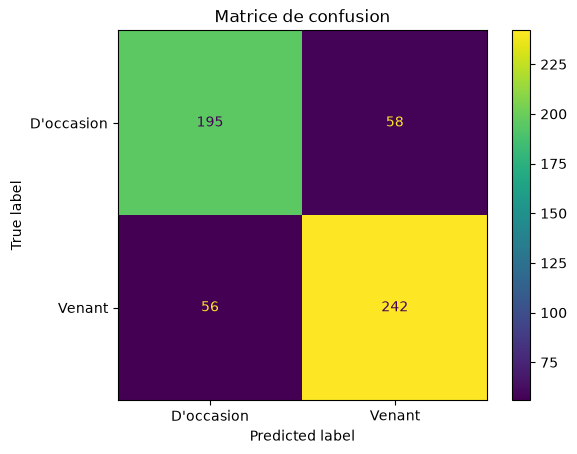

In [35]:
# Matrice de confusion
CM_visualisation(lg_model)

### <font color = 'teal'>Decision Tree<font>

###### <font color = 'bisque'> Recherche des paramètre optimaux

In [36]:
# Recherche des paramètres optimaux pour le Decision Tree
from sklearn.tree import DecisionTreeClassifier
cv = KFold(n_splits = 5, shuffle =True, random_state= 42)

# dictionnaire des params
params_dt = {'criterion':['gini','entropy'],'max_depth':np.arange(3,15)}
# instantier le modèle Decision Tree
dt = DecisionTreeClassifier(random_state = 42)
# instantier le modèle gridsearch
grid_dt = GridSearchCV(dt, params_dt, cv = cv, n_jobs = -1)
# entrainer le modèle
grid_dt.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['gini', 'entropy'], 'max_depth': array([ 3, 4..., 12, 13, 14])}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, 

In [37]:
# afficher les paramètres optimaux
grid_dt.best_params_

{'criterion': 'entropy', 'max_depth': np.int64(4)}

###### <font color = 'bisque'> Entrainement du modèle

In [38]:
# Récupérer le modèle optimal
tree_model = grid_dt.best_estimator_

###### <font color = 'bisque'> Evaluation du modèle

In [39]:
# Accuracy et F1 score du modèle sur les données de validation
acc_tree ,f1_tree = evaluation(tree_model)
print(f"accuracy : {acc_tree} -------F1-Score : {f1_tree}")

accuracy : 0.8112522686025408 -------F1-Score : 0.8104326569742984


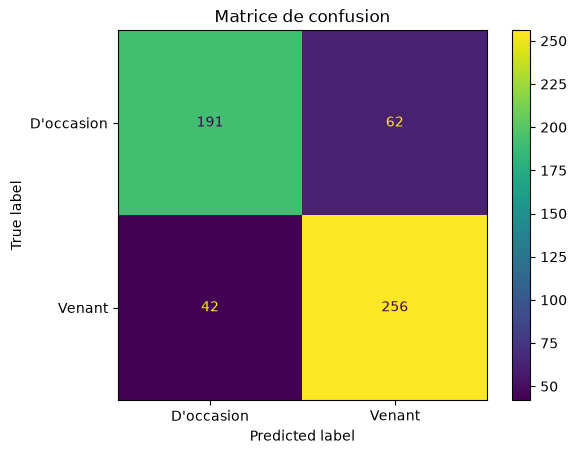

In [40]:
# Matrice de confusion
CM_visualisation(tree_model)

### <font color = 'teal'>Random Forest<font>

In [41]:
# Recherche des paramètres optimaux pour le Random Forest
from sklearn.ensemble import RandomForestClassifier
# dictionnaire des  params
params_rf = {
    'n_estimators': list(np.arange(10,100,10)),
    'max_depth' : list(np.arange(3,15)),
    'criterion' :['gini', 'entropy']
}
cv = KFold(n_splits = 5, shuffle =True, random_state= 42)

# instantier le modèle Random Forest
rf = RandomForestClassifier(random_state = 42)
# instantier le modèle gridsearch
grid_rf = GridSearchCV(estimator=rf, param_grid=params_rf, cv= cv, n_jobs = -1)
# entrainer le modèle
grid_rf.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['gini', 'entropy'], 'max_depth': [np.int64(3), np.int64(4), ...], 'n_estimators': [np.int64(10), np.int64(20), ...]}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Suppo

In [45]:
# Afficher les paramètres optimaux
grid_rf.best_params_

{'criterion': 'entropy',
 'max_depth': np.int64(8),
 'n_estimators': np.int64(60)}

In [43]:
# Récupérer le modèle optimal
rf_model = grid_rf.best_estimator_

##### <font color ='bisque'>Evaluation du Random Forest<font>

In [46]:
# Accuracy et F1 score du modèle sur les données de validation
acc_rf ,f1_rf = evaluation(rf_model)
print(f"accuracy : {acc_rf} -------F1-Score : {f1_rf}")

accuracy : 0.8130671506352087 -------F1-Score : 0.811306012623488


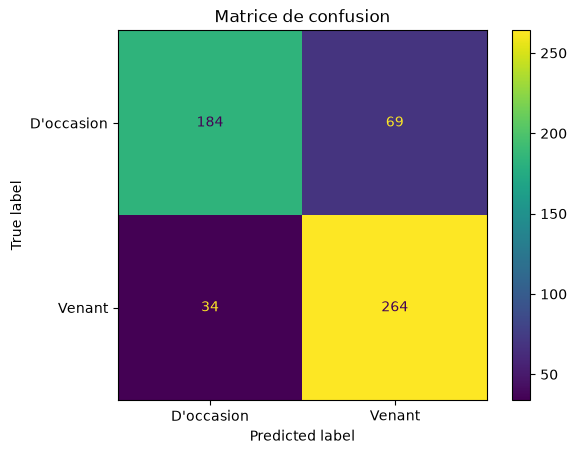

In [47]:
# Matrice de confusion
CM_visualisation(rf_model)

### <font color = 'teal'>Comparaison des modèles<font>

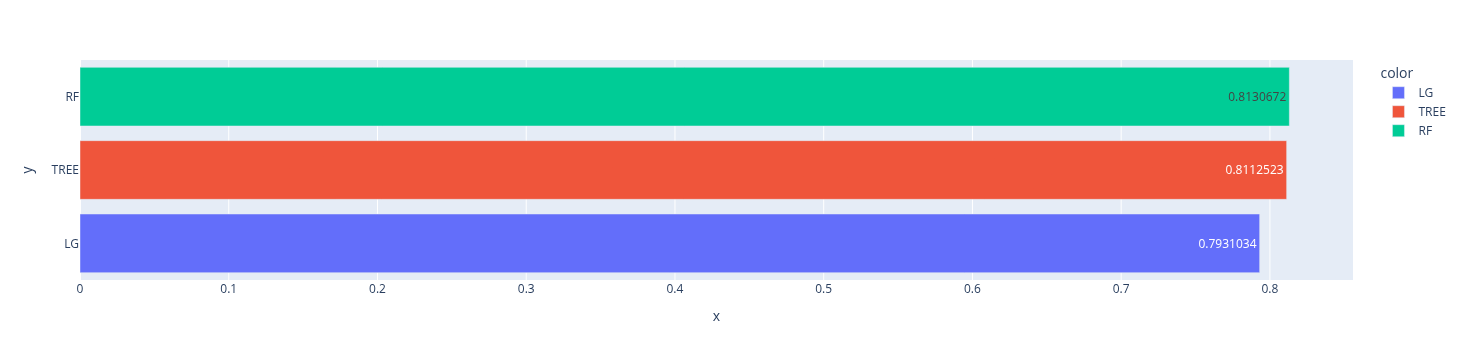

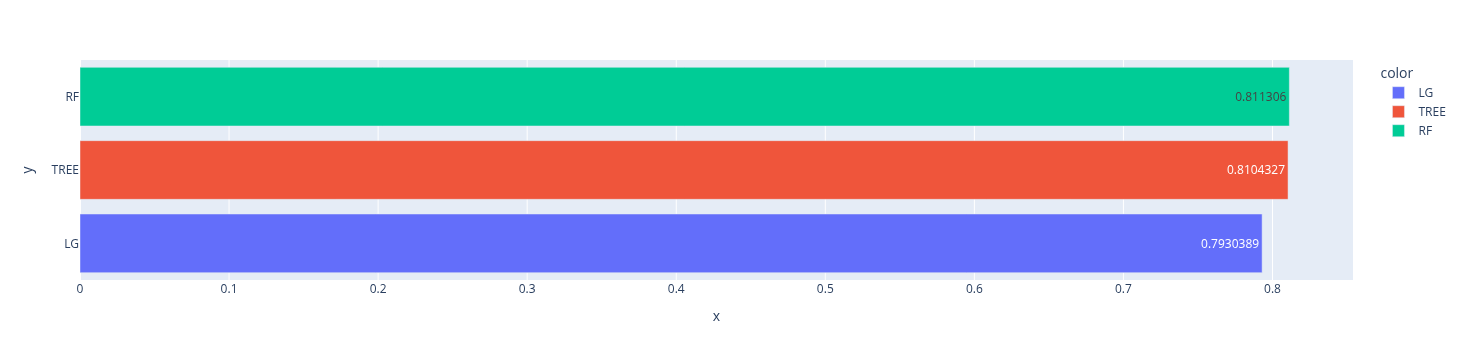

In [48]:
# diagramme de performances
list_names = ['LG', 'TREE','RF']
list_acc = [acc_lg, acc_tree, acc_rf]
list_f1 = [f1_lg,f1_tree, f1_rf]
list_final = [list_acc, list_f1]

for i in range(2):

    fig = px.bar(y = list_names, x = list_final[i], color = list_names, text_auto = True)
    fig.show()

### <font color = 'teal'>Sélection et sauvegarde du modèle le plus performant<font>

In [49]:
# le modèle retenu est celui qui a la meilleure accuracy sur les données de validation
models = {'LG': lg_model, 'TREE': tree_model, 'RF': rf_model}
best_name = list_names[int(np.argmax(list_acc))]
best_model = models[best_name]
print(f"Modèle le plus performant : {best_name} (accuracy validation = {max(list_acc):.4f})")

Modèle le plus performant : RF (accuracy validation = 0.8131)


In [50]:
# téléchargement le modèle le plus performant
jb.dump(best_model, "./models/voiture_model.joblib")

['./models/voiture_model.joblib']

### <font color ='bisque'>Tester le modèle le plus performant<font>

In [51]:
# Evaluation du modèle retenu sur les données de test
from sklearn.metrics import classification_report
y_pred_test = best_model.predict(x_test)
print(f"accuracy (test) : {accuracy_score(y_test, y_pred_test):.4f}")
print(classification_report(y_test, y_pred_test, target_names = classnames))

accuracy (test) : 0.7949
              precision    recall  f1-score   support

  D'occasion       0.85      0.71      0.78       274
      Venant       0.75      0.88      0.81       277

    accuracy                           0.79       551
   macro avg       0.80      0.79      0.79       551
weighted avg       0.80      0.79      0.79       551



In [52]:
# echantillons
x_test_10 = x_test[:10]
y_test_10 = y_test[:10]

# predictions
y_pred_10 = best_model.predict(x_test_10)
# retrouver les libellés d'origine à partir des codes
pred_names = encoders['Venant_Occasion'].inverse_transform(y_pred_10)
real_names = encoders['Venant_Occasion'].inverse_transform(y_test_10)

for i in range(10):
    print(f"Prédiction {i + 1} : {pred_names[i]} -- Réel : {real_names[i]}")

Prédiction 1 : D'occasion -- Réel : D'occasion
Prédiction 2 : Venant -- Réel : Venant
Prédiction 3 : D'occasion -- Réel : D'occasion
Prédiction 4 : Venant -- Réel : Venant
Prédiction 5 : D'occasion -- Réel : Venant
Prédiction 6 : D'occasion -- Réel : D'occasion
Prédiction 7 : Venant -- Réel : Venant
Prédiction 8 : Venant -- Réel : D'occasion
Prédiction 9 : D'occasion -- Réel : Venant
Prédiction 10 : D'occasion -- Réel : D'occasion
